<a href="https://colab.research.google.com/github/clobos/ECO5056_2026/blob/main/Redes_Neurais_Profundas_ECO5056.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# REDES NEURAIS PROFUNDAS COM TENSORFLOW




In [2]:
import os  # biblioteca do sistema operacional (caminhos de pasta)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2" # esconde mensagens internas e verbosas do TensorFlow
import numpy as np     # álgebra linear e vetores/matrizes
import matplotlib      # biblioteca de gráficos
matplotlib.use("Agg")  # usa backend sem janela: salva figuras em arquivo
import matplotlib.pyplot as plt  # interface de desenho do matplotlib
import tensorflow as tf  # motor de cálculo (diferenciação automática, GPU/CPU)
from tensorflow import keras           # API de alto nível para construir redes
from tensorflow.keras import layers    # camadas densas, dropout etc.
from sklearn.datasets import load_diabetes, load_breast_cancer   # dois conjuntos de dados reais
from sklearn.model_selection import train_test_split # separa treino e teste
from sklearn.preprocessing import StandardScaler # padronização (média 0, desvio 1)
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             confusion_matrix, roc_curve, roc_auc_score, accuracy_score)

keras.utils.set_random_seed(42)    # fixa sementes: resultados reproduzíveis




# FUNÇÃO PARA CONSTRUIR A REDE MLP (perceptron multicamadas)

In [3]:
def build_mlp(n_features, task, lr=1e-3, dropout=0.2, hidden=(64, 32)):
    # n_features: número de entradas (colunas de X)
    # task: "regression" ou "classification"
    # lr: taxa de aprendizado do otimizador Adam
    # dropout: fração de neurônios desligados em cada passo de treino
    # hidden: tupla com o número de neurônios de cada camada oculta
    model = keras.Sequential(name=f"mlp_{task}")   # rede sequencial: camada após camada
    model.add(layers.Input(shape=(n_features,)))   # declara o formato da entrada (sem camada de cálculo)
    for units in hidden:                           # para cada camada oculta...
        model.add(layers.Dense(units,              # ...camada totalmente conectada com 'units' neurônios
                               activation="relu",  # função de ativação ReLU: max(0, z)
                               kernel_initializer="he_normal"))  # inicialização de pesos recomendada para ReLU
        if dropout > 0:                            # se houver dropout...
            model.add(layers.Dropout(dropout))     # ...zera uma fração aleatória de ativações (só no treino)
    if task == "regression":        # saída para regressão
        model.add(layers.Dense(1, activation="linear"))          # 1 neurônio, sem função de ativação (valor real)
        loss = "mse"                  # função de perda: erro quadrático médio
        metrics = ["mae"]             # métrica extra: erro absoluto médio
    else:                        # saída para classificação binária
        model.add(layers.Dense(1, activation="sigmoid"))         # sigmoide: converte em probabilidade entre 0 e 1
        loss = "binary_crossentropy" # função de perda: entropia cruzada binária
        metrics = ["accuracy", keras.metrics.AUC(name="auc")]    # acurácia e área sob a curva ROC
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),  # otimizador Adam com taxa lr
                  loss=loss,              # perda que será minimizada
                  metrics=metrics)        # métricas apenas para acompanhar
    return model                          # devolve a rede pronta para treinar




# REGRESSÃO (diabetes)

In [4]:
data = load_diabetes()                             # carrega o conjunto de dados
X, y = data.data, data.target                      # X: matriz (442 x 10); y: progressão da doença (número real)
print("Formato de X:", X.shape, "| formato de y:", y.shape)

# Separação treino (80%) e teste (20%). O TESTE NÃO É USADO PARA AJUSTAR NADA.
X_trv, X_te, y_trv, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

# Padronização: o escalonamento é ajustado SOMENTE no treino (evita vazamento de informação).
x_scaler = StandardScaler().fit(X_trv)  # aprende média e desvio-padrão das entradas do treino
y_scaler = StandardScaler().fit(y_trv.reshape(-1, 1))  # idem para a saída (ajuda a estabilizar o treino)
Xs_trv = x_scaler.transform(X_trv) # entradas do treino padronizadas
Xs_te = x_scaler.transform(X_te)   # entradas do teste padronizadas com a MESMA escala
ys_trv = y_scaler.transform(y_trv.reshape(-1, 1)).ravel()  # alvo do treino padronizado (vetor 1D)

reg = build_mlp(n_features=X.shape[1], task="regression",
                lr=1e-3, dropout=0.2, hidden=(64, 32))  # cria a rede: 10 -> 64 -> 32 -> 1
reg.summary()               # imprime a arquitetura e o número de parâmetros

# Parada antecipada: monitora a perda de validação e para quando ela deixa de melhorar.
early_reg = keras.callbacks.EarlyStopping(
    monitor="val_loss",  # quantidade observada: perda no conjunto de validação
    patience=25,         # tolera 25 épocas sem melhora antes de parar
    restore_best_weights=True)  # ao parar, devolve os pesos da melhor época

hist_reg = reg.fit(Xs_trv, ys_trv, # treina com as entradas e o alvo padronizados
                   validation_split=0.2, # reserva 20% do treino para validação
                   epochs=500,   # no máximo 500 passagens completas pelos dados
                   batch_size=32,# tamanho do lote: 32 exemplos por atualização de pesos
                   callbacks=[early_reg], # ativa a parada antecipada
                   shuffle=True,          # embaralha os exemplos a cada época
                   verbose=0)          # não imprime o progresso de cada época
print("Épocas executadas:", len(hist_reg.history["loss"]),
      "| melhor época:", int(np.argmin(hist_reg.history["val_loss"])) + 1)

# Predição no teste e volta à escala original (inverse_transform desfaz a padronização)
pred_te_s = reg.predict(Xs_te, verbose=0)  # saída da rede na escala padronizada
pred_te = y_scaler.inverse_transform(pred_te_s).ravel()  # converte para a escala original do alvo

rmse = np.sqrt(mean_squared_error(y_te, pred_te))  # raiz do erro quadrático médio
mae = mean_absolute_error(y_te, pred_te)   # erro absoluto médio
r2 = r2_score(y_te, pred_te)               # proporção da variância explicada
print(f"TESTE -> RMSE: {rmse:.2f} | MAE: {mae:.2f} | R²: {r2:.3f}")

Formato de X: (442, 10) | formato de y: (442,)


Model: "mlp_regression"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,817 (11.00 KB)

 Trainable params: 2,817 (11.00 KB)

 Non-trainable params: 0 (0.00 B)

Épocas executadas: 86 | melhor época: 61
TESTE -> RMSE: 54.13 | MAE: 44.41 | R²: 0.447


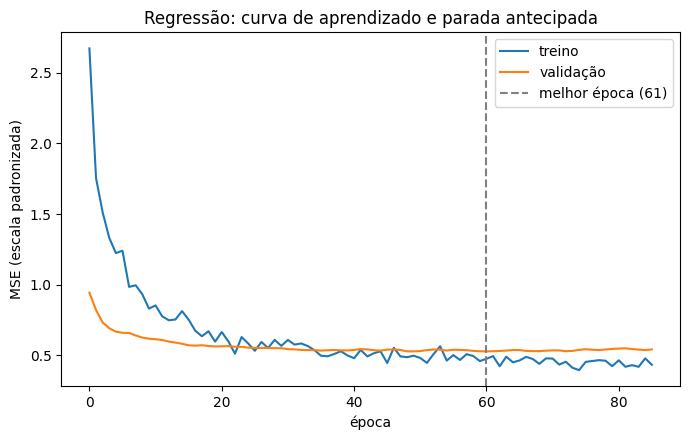

In [5]:
# Força o matplotlib a renderizar os gráficos diretamente no notebook
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

# --- Gráfico 1: curvas de perda (treino x validação) com a época ótima marcada ---
fig, ax = plt.subplots(figsize=(7, 4.5))           # Cria uma figura e eixo individual
ax.plot(hist_reg.history["loss"], label="treino")  # perda de treino a cada época
ax.plot(hist_reg.history["val_loss"], label="validação")  # perda de validação a cada época
best = int(np.argmin(hist_reg.history["val_loss"]))
ax.axvline(best, ls="--", c="gray", label=f"melhor época ({best+1})")  # linha vertical
ax.set_xlabel("época"); ax.set_ylabel("MSE (escala padronizada)")
ax.set_title("Regressão: curva de aprendizado e parada antecipada")
ax.legend()
fig.tight_layout()
plt.show()                                         # mostra o primeiro gráfico

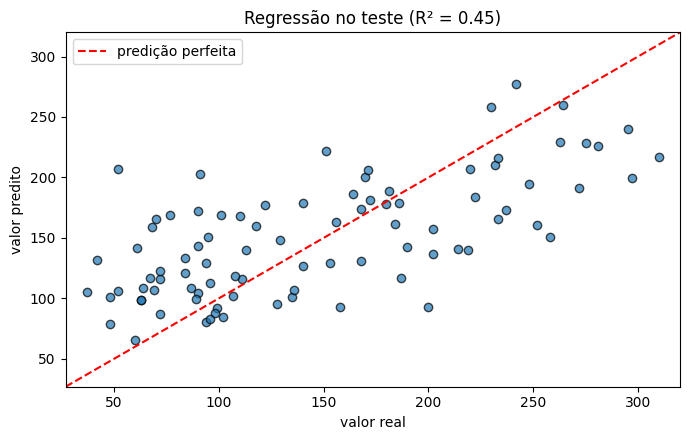

In [6]:
# --- Gráfico 2: real x predito no teste ---
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(y_te, pred_te, alpha=0.7, edgecolor="k")  # cada ponto é um paciente do teste
lims = [min(y_te.min(), pred_te.min()) - 10, max(y_te.max(), pred_te.max()) + 10]
ax.plot(lims, lims, "r--", label="predição perfeita")  # linha y = x
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("valor real"); ax.set_ylabel("valor predito")
ax.set_title(f"Regressão no teste (R² = {r2:.2f})"); ax.legend()
fig.tight_layout()
plt.show()           # mostra o segundo gráfico

# CLASSIFICAÇÃO BINÁRIA (câncer de mama: maligno = 0, benigno = 1)

In [7]:
cancer = load_breast_cancer()                      # carrega o conjunto de dados
Xc, yc = cancer.data, cancer.target                # Xc: 569 x 30; yc: rótulos 0 ou 1
print("Formato de Xc:", Xc.shape, "| classes:", dict(zip(cancer.target_names, np.bincount(yc))))

# stratify=yc mantém a proporção das classes igual no treino e no teste
Xc_trv, Xc_te, yc_trv, yc_te = train_test_split(Xc, yc, test_size=0.2, stratify=yc, random_state=42)
sc = StandardScaler().fit(Xc_trv)   # padronizador ajustado só no treino
Xc_trv_s = sc.transform(Xc_trv)     # treino padronizado
Xc_te_s = sc.transform(Xc_te)       # teste padronizado com a mesma escala



Formato de Xc: (569, 30) | classes: {np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}


# BUSCA DE HIPERPARÂMETROS (grade simples), escolhida pela perda de VALIDAÇÃO

In [ ]:
grid = [{"lr": lr, "dropout": d, "batch": b} # cada dicionário é uma combinação
        for lr in [1e-2, 1e-3]               # taxa de aprendizado
        for d in [0.0, 0.3]                  # taxa de dropout
        for b in [16, 64]]                   # tamanho do lote
resultados = []                         # guarda o resultado de cada combinação
for g in grid:
    keras.utils.set_random_seed(42)     # mesma semente para comparação justa
    m = build_mlp(Xc.shape[1], "classification", lr=g["lr"], dropout=g["dropout"], hidden=(32, 16))
    h = m.fit(Xc_trv_s, yc_trv,               # treina com o treino padronizado
              validation_split=0.2, epochs=300, # 20% do treino vira validação
              batch_size=g["batch"],
              callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=20,
                                                       restore_best_weights=True)],
              verbose=0)
    melhor_val = float(np.min(h.history["val_loss"]))
    melhor_ep = int(np.argmin(h.history["val_loss"])) + 1
    resultados.append((g, melhor_val, melhor_ep, h.history))
    print(f"lr={g['lr']:<6} dropout={g['dropout']:<4} lote={g['batch']:<3} "
          f"-> val_loss={melhor_val:.4f} (época {melhor_ep})")

melhor = min(resultados, key=lambda r: r[1])  # escolhe a combinação de menor perda de validação
hp = melhor[0]
print("\nMelhores hiperparâmetros:", hp)

lr=0.01   dropout=0.0  lote=16  -> val_loss=0.0260 (época 12)
lr=0.01   dropout=0.0  lote=64  -> val_loss=0.0124 (época 20)
lr=0.01   dropout=0.3  lote=16  -> val_loss=0.0141 (época 26)
lr=0.01   dropout=0.3  lote=64  -> val_loss=0.0135 (época 60)
lr=0.001  dropout=0.0  lote=16  -> val_loss=0.0146 (época 79)
lr=0.001  dropout=0.0  lote=64  -> val_loss=0.0149 (época 224)


In [ ]:
# Gráfico 3: curvas de validação das 8 combinações (efeito da taxa de aprendizado e do lote)
%matplotlib inline
fig, ax = plt.subplots(figsize=(7, 4.5))
for g, _, _, hist in resultados:
    ax.plot(hist["val_loss"], label=f"lr={g['lr']}, drop={g['dropout']}, lote={g['batch']}")
ax.set_xlabel("época"); ax.set_ylabel("perda de validação")
ax.set_title("Classificação: efeito de lr, dropout e lote na validação")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

# TREINO FINAL com os melhores hiperparâmetros e avaliação no TESTE

In [ ]:
keras.utils.set_random_seed(42)
clf = build_mlp(Xc.shape[1], "classification", lr=hp["lr"], dropout=hp["dropout"], hidden=(32, 16))
hist_clf = clf.fit(Xc_trv_s, yc_trv, validation_split=0.2, epochs=300, batch_size=hp["batch"],
                   callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=20,
                   restore_best_weights=True)],
                   verbose=0)
prob_te = clf.predict(Xc_te_s, verbose=0).ravel()     # probabilidade de ser benigno (classe 1), entre 0 e 1
yhat_te = (prob_te >= 0.5).astype(int)                # limiar 0,5: acima vira classe 1
acc = accuracy_score(yc_te, yhat_te)                  # proporção de acertos
auc = roc_auc_score(yc_te, prob_te)                   # área sob a curva ROC (independe do limiar)
cm = confusion_matrix(yc_te, yhat_te)                 # matriz de confusão
print(f"TESTE -> acurácia: {acc:.3f} | AUC: {auc:.3f}")
print("Matriz de confusão (linhas = real, colunas = predito):\n", cm)


In [ ]:
# Gráfico 4: curva de aprendizado do modelo final
%matplotlib inline
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(hist_clf.history["loss"], label="treino")
ax.plot(hist_clf.history["val_loss"], label="validação")
best = int(np.argmin(hist_clf.history["val_loss"]))
ax.axvline(best, ls="--", c="gray", label=f"melhor época ({best+1})")
ax.set_xlabel("época"); ax.set_ylabel("entropia cruzada binária")
ax.set_title("Classificação: curva de aprendizado (modelo final)")
ax.legend()
fig.tight_layout()
plt.show()

In [ ]:
# Gráfico 5: curva ROC no teste
%matplotlib inline
fpr, tpr, _ = roc_curve(yc_te, prob_te)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(fpr, tpr, label=f"rede neural (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", label="acaso")
ax.set_xlabel("falso positivo"); ax.set_ylabel("verdadeiro positivo")
ax.set_title("Curva ROC no teste"); ax.legend()
fig.tight_layout()
plt.show()

In [ ]:
# Gráfico 6.1: funções de ativação comparadas (1 linha x 3 colunas, mesma escala y)
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

z = np.linspace(-5, 5, 400)                           # 400 pontos entre -5 e 5
sigm = 1 / (1 + np.exp(-z))                           # sigmoide

# Criando figura com 1 linha e 3 colunas compartilhando o mesmo eixo y
fig1, axs = plt.subplots(1, 3, figsize=(12, 4.2), sharey=True)

# Subplot 1: Sigmoide
axs[0].plot(z, sigm, label="sigmoide", color="C0")
axs[0].axhline(0, color="gray", linestyle="--")
axs[0].axvline(0, color="gray", linestyle="--")
axs[0].set_title("Sigmoide")
axs[0].set_xlabel("z")
axs[0].grid(alpha=0.3)

# Subplot 2: Tanh
axs[1].plot(z, np.tanh(z), label="tanh", color="C1")
axs[1].axhline(0, color="gray", linestyle="--")
axs[1].axvline(0, color="gray", linestyle="--")
axs[1].set_title("Tanh")
axs[1].set_xlabel("z")
axs[1].grid(alpha=0.3)

# Subplot 3: ReLU
axs[2].plot(z, np.maximum(0, z), label="ReLU", color="C2")
axs[2].axhline(0, color="gray", linestyle="--")
axs[2].axvline(0, color="gray", linestyle="--")
axs[2].set_title("ReLU")
axs[2].set_xlabel("z")
axs[2].grid(alpha=0.3)

fig1.tight_layout()
plt.show()

In [ ]:
# Gráfico 6.2: derivadas das funções de ativação comparadas (1 linha x 3 colunas, mesma escala y)
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

z = np.linspace(-5, 5, 400)
sigm = 1 / (1 + np.exp(-z))

# Criando figura com 1 linha e 3 colunas compartilhando o mesmo eixo y
fig2, axs2 = plt.subplots(1, 3, figsize=(12, 4.2), sharey=True)

# Subplot 1: Derivada da Sigmoide
deriv_sigm = sigm * (1 - sigm)
axs2[0].plot(z, deriv_sigm, label="d_sigmoide", color="C0")
axs2[0].axhline(0, color="gray", linestyle="--")
axs2[0].axvline(0, color="gray", linestyle="--")
axs2[0].set_title("Derivada da Sigmoide")
axs2[0].set_xlabel("z")
axs2[0].grid(alpha=0.3)

# Subplot 2: Derivada da Tanh
deriv_tanh = 1 - np.tanh(z)**2
axs2[1].plot(z, deriv_tanh, label="d_tanh", color="C1")
axs2[1].axhline(0, color="gray", linestyle="--")
axs2[1].axvline(0, color="gray", linestyle="--")
axs2[1].set_title("Derivada da Tanh")
axs2[1].set_xlabel("z")
axs2[1].grid(alpha=0.3)

# Subplot 3: Derivada da ReLU
deriv_relu = np.where(z > 0, 1, 0)
axs2[2].plot(z, deriv_relu, label="d_ReLU", color="C2")
axs2[2].axhline(0, color="gray", linestyle="--")
axs2[2].axvline(0, color="gray", linestyle="--")
axs2[2].set_title("Derivada da ReLU")
axs2[2].set_xlabel("z")
axs2[2].grid(alpha=0.3)

fig2.tight_layout()
plt.show()